# DATA SCIENCE INTERN @OASIS INFOBYTE

## AUTHOR : SHREENIDHI MEDAR

# TASK 5: Sales Prediction Using Python

# 1.Import necessary libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

# Consistent chart appearance
sns.set_theme(style="whitegrid", palette="deep")

print("Basic libraries imported successfully.")

Basic libraries imported successfully.


## 2. Load the Dataset

In [2]:
from pathlib import Path

file_path = Path("Advertising.csv")

if not file_path.exists():
    raise FileNotFoundError(
        "Advertising.csv was not found. Download the dataset from Kaggle "
        "and place it in the notebook folder, or update file_path with its full location."
    )

df = pd.read_csv(file_path)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully.
Dataset shape: (200, 4)


,TV,Radio,Newspaper,Sales
0,230.100,37.800,69.200,22.100
1,44.500,39.300,45.100,10.400
2,17.200,45.900,69.300,12.000
3,151.500,41.300,58.500,16.500
4,180.800,10.800,58.400,17.900


## 3. Initial Data Inspection

In [3]:
print("Dataset dimensions:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nFirst five rows:")
display(df.head())

print("\nDescriptive statistics:")
display(df.describe(include="all"))

Dataset dimensions: (200, 4)

Column names:
['TV', 'Radio', 'Newspaper', 'Sales']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB

First five rows:


,TV,Radio,Newspaper,Sales
0,230.100,37.800,69.200,22.100
1,44.500,39.300,45.100,10.400
2,17.200,45.900,69.300,12.000
3,151.500,41.300,58.500,16.500
4,180.800,10.800,58.400,17.900



Descriptive statistics:


,TV,Radio,Newspaper,Sales
count,200.000,200.000,200.000,200.000
mean,147.042,23.264,30.554,15.131
std,85.854,14.847,21.779,5.284
min,0.700,0.000,0.300,1.600
25%,74.375,9.975,12.750,11.000
50%,149.750,22.900,25.750,16.000
75%,218.825,36.525,45.100,19.050
max,296.400,49.600,114.000,27.000


## 4. Data Pre-processing and Quality Checks

In [4]:
# Standardize column names by removing leading/trailing spaces
df.columns = df.columns.str.strip()

# Remove an exported index column if present
index_columns = [col for col in df.columns if col.lower().startswith("unnamed:")]
if index_columns:
    df = df.drop(columns=index_columns)
    print("Removed unnecessary index column(s):", index_columns)

# Confirm required columns
required_columns = ["TV", "Radio", "Newspaper", "Sales"]
missing_columns = [col for col in required_columns if col not in df.columns]

if missing_columns:
    raise ValueError(f"Required column(s) missing from dataset: {missing_columns}")

# Keep only the required project features
df = df[required_columns].copy()

# Convert expected columns to numeric; non-numeric values become NaN for inspection
for col in required_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("Missing values by column:")
display(df.isnull().sum().to_frame("Missing Values"))

print("Duplicate rows:", df.duplicated().sum())

print("Data types:")
display(df.dtypes.to_frame("Data Type"))

print("Negative values by column:")
display((df < 0).sum().to_frame("Negative Values"))

Missing values by column:


,Missing Values
TV,0
Radio,0
Newspaper,0
Sales,0


Duplicate rows: 0
Data types:


,Data Type
TV,float64
Radio,float64
Newspaper,float64
Sales,float64


Negative values by column:


,Negative Values
TV,0
Radio,0
Newspaper,0
Sales,0


In [5]:
# Remove exact duplicate rows, if any
rows_before = len(df)
df = df.drop_duplicates().copy()
duplicates_removed = rows_before - len(df)

# Remove rows with missing or non-numeric values in required columns
rows_before_missing = len(df)
df = df.dropna(subset=required_columns).copy()
missing_rows_removed = rows_before_missing - len(df)

print(f"Duplicate rows removed: {duplicates_removed}")
print(f"Rows removed due to missing/non-numeric required values: {missing_rows_removed}")
print("Shape after these cleaning steps:", df.shape)

# Check whether any negative values remain
negative_counts = (df < 0).sum()
display(negative_counts.to_frame("Negative Values Remaining"))

if (df < 0).any().any():
    raise ValueError(
        "Negative values were found in the advertising or sales columns. "
        "Investigate these records before modeling; do not remove them without justification."
    )

print("Final missing-value count:", int(df.isnull().sum().sum()))
print("Final duplicate-row count:", int(df.duplicated().sum()))

display(df.head())

Duplicate rows removed: 0
Rows removed due to missing/non-numeric required values: 0
Shape after these cleaning steps: (200, 4)


,Negative Values Remaining
TV,0
Radio,0
Newspaper,0
Sales,0


Final missing-value count: 0
Final duplicate-row count: 0


,TV,Radio,Newspaper,Sales
0,230.100,37.800,69.200,22.100
1,44.500,39.300,45.100,10.400
2,17.200,45.900,69.300,12.000
3,151.500,41.300,58.500,16.500
4,180.800,10.800,58.400,17.900


## 5. Exploratory Data Analysis (EDA)

EDA helps us understand the distribution of advertising expenditure and sales before fitting models.

In [6]:
print("Cleaned dataset shape:", df.shape)
display(df.describe())

Cleaned dataset shape: (200, 4)


,TV,Radio,Newspaper,Sales
count,200.000,200.000,200.000,200.000
mean,147.042,23.264,30.554,15.131
std,85.854,14.847,21.779,5.284
min,0.700,0.000,0.300,1.600
25%,74.375,9.975,12.750,11.000
50%,149.750,22.900,25.750,16.000
75%,218.825,36.525,45.100,19.050
max,296.400,49.600,114.000,27.000


### 5.1 Distribution of Each Feature

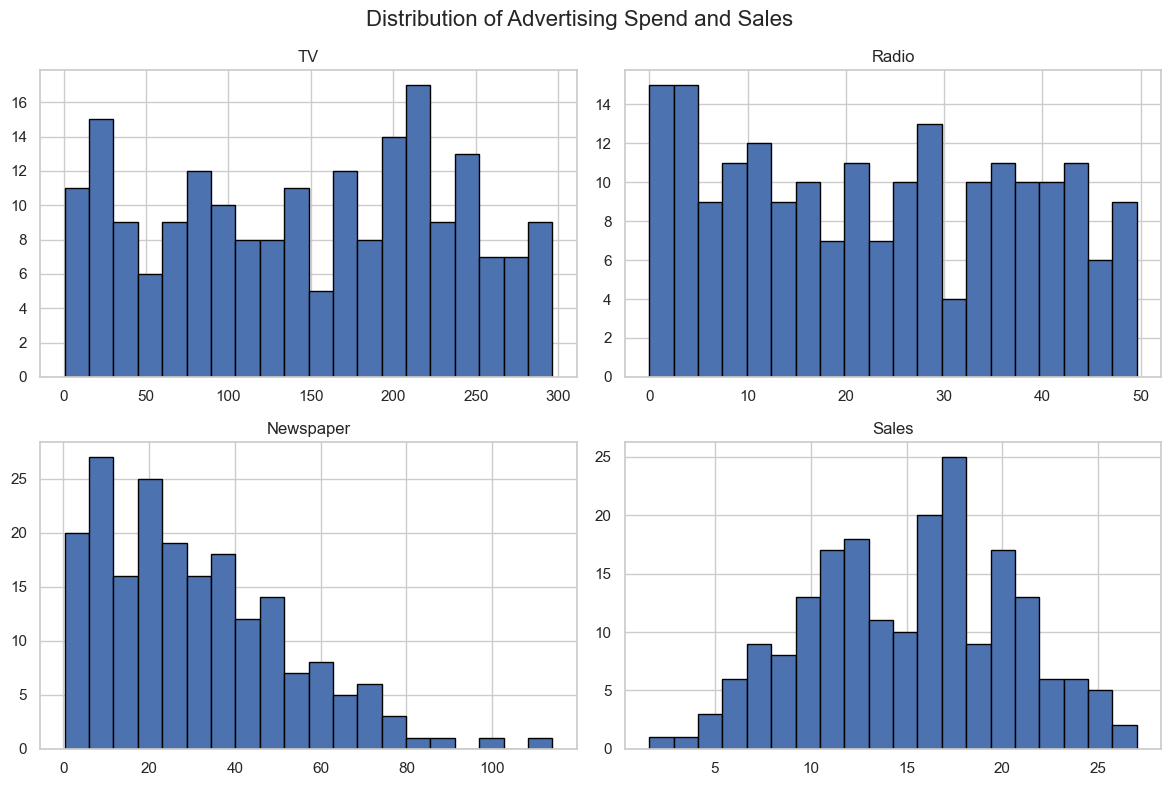

In [7]:
df.hist(figsize=(12, 8), bins=20, edgecolor="black")
plt.suptitle("Distribution of Advertising Spend and Sales", fontsize=16)
plt.tight_layout()
plt.show()

### 5.2 Pairplot of All Features

C:\Users\Shreenidhi Medar\AppData\Local\Programs\Python\Python310\lib\site-packages\seaborn\axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


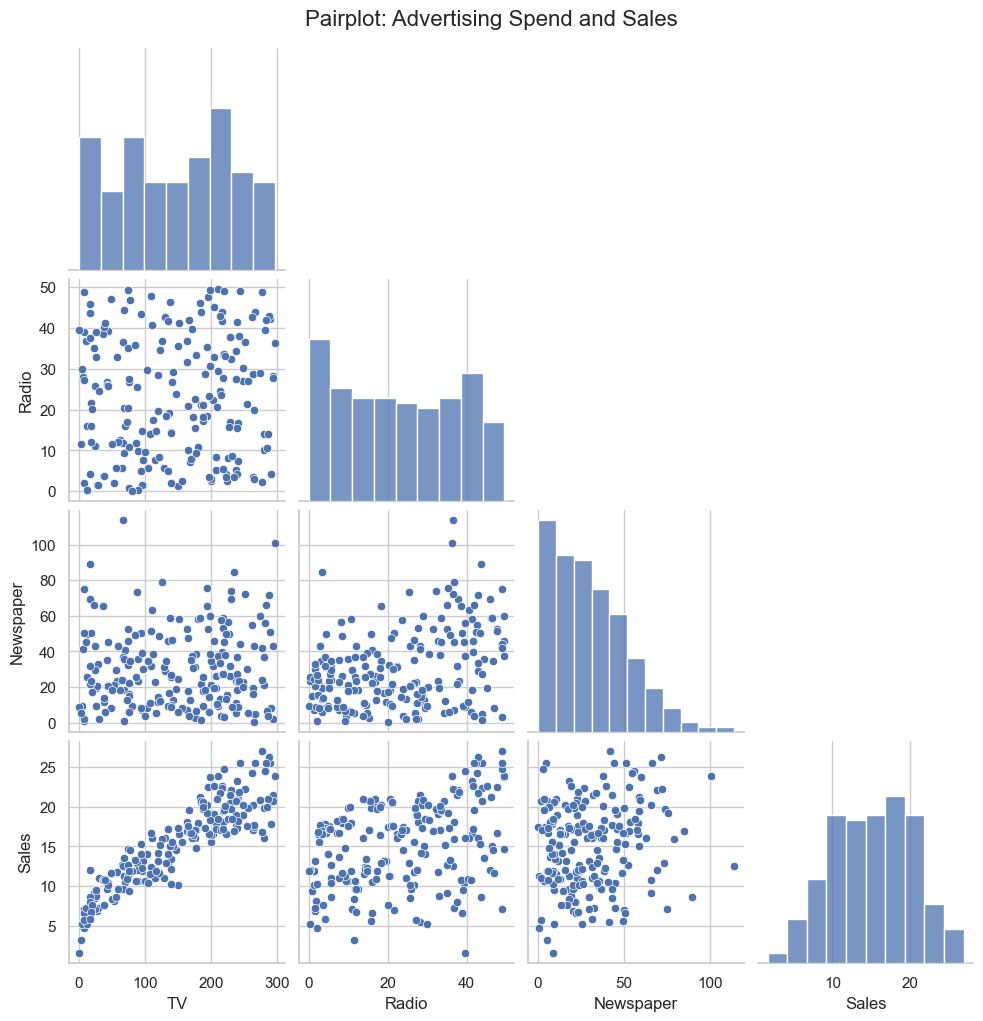

In [8]:
sns.pairplot(df, diag_kind="hist", corner=True)
plt.suptitle("Pairplot: Advertising Spend and Sales", y=1.02, fontsize=16)
plt.show()

## 6. Individual Scatter Plots: Advertising Spend vs. Sales

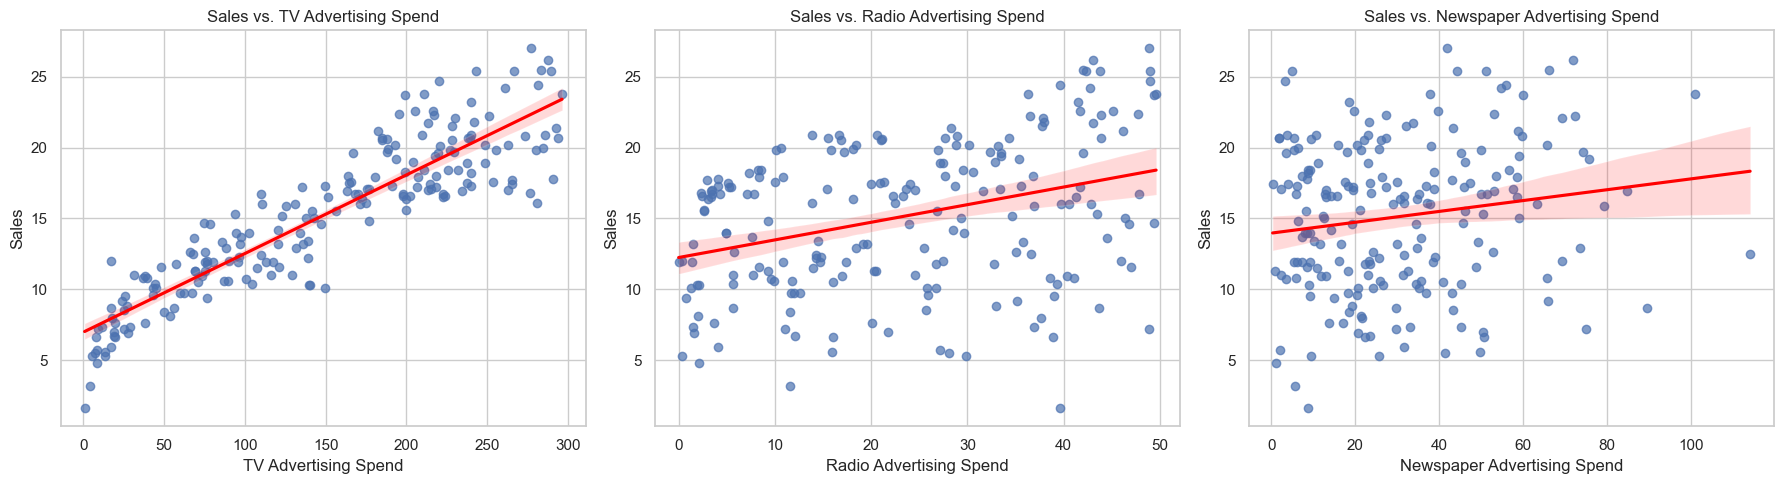

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

channels = ["TV", "Radio", "Newspaper"]

for ax, channel in zip(axes, channels):
    sns.regplot(
        data=df, x=channel, y="Sales", ax=ax,
        scatter_kws={"alpha": 0.7}, line_kws={"color": "red"}
    )
    ax.set_title(f"Sales vs. {channel} Advertising Spend")
    ax.set_xlabel(f"{channel} Advertising Spend")
    ax.set_ylabel("Sales")

plt.tight_layout()
plt.show()

### 6.1 TV Advertising vs. Sales

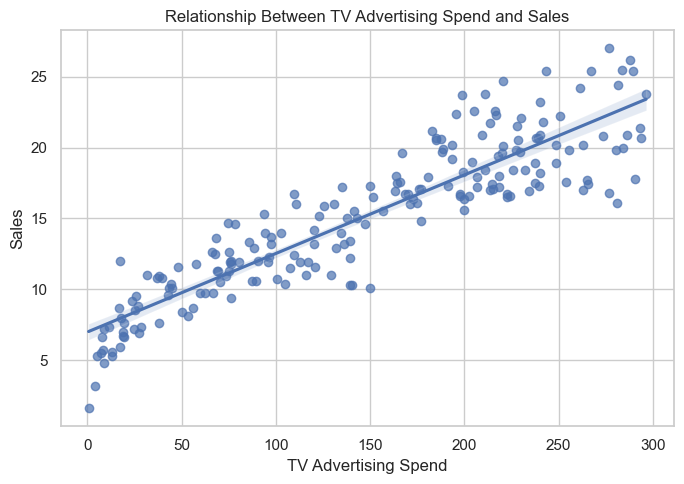

In [10]:
plt.figure(figsize=(7, 5))
sns.regplot(data=df, x="TV", y="Sales", scatter_kws={"alpha": 0.7})
plt.title("Relationship Between TV Advertising Spend and Sales")
plt.xlabel("TV Advertising Spend")
plt.ylabel("Sales")
plt.tight_layout()
plt.show()

### 6.2 Radio Advertising vs. Sales

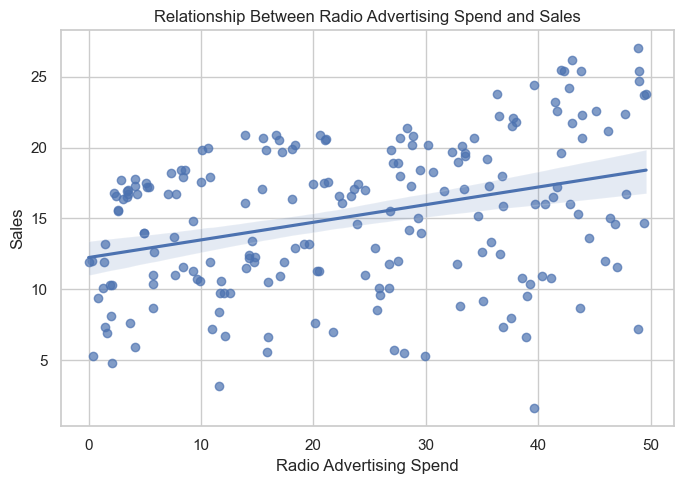

In [11]:
plt.figure(figsize=(7, 5))
sns.regplot(data=df, x="Radio", y="Sales", scatter_kws={"alpha": 0.7})
plt.title("Relationship Between Radio Advertising Spend and Sales")
plt.xlabel("Radio Advertising Spend")
plt.ylabel("Sales")
plt.tight_layout()
plt.show()

### 6.3 Newspaper Advertising vs. Sales

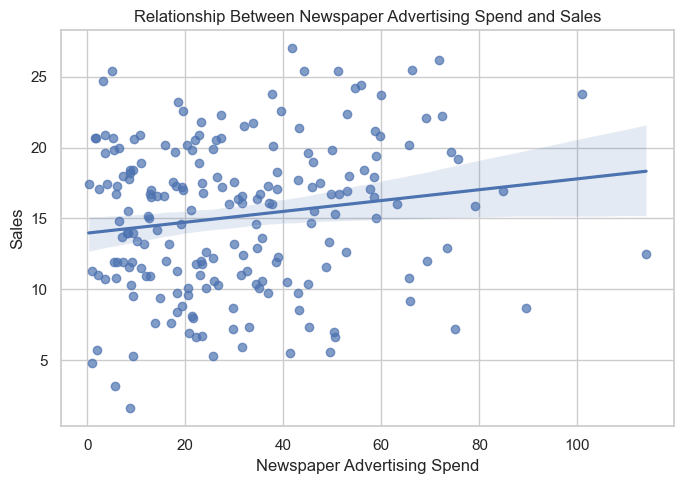

In [12]:
plt.figure(figsize=(7, 5))
sns.regplot(data=df, x="Newspaper", y="Sales", scatter_kws={"alpha": 0.7})
plt.title("Relationship Between Newspaper Advertising Spend and Sales")
plt.xlabel("Newspaper Advertising Spend")
plt.ylabel("Sales")
plt.tight_layout()
plt.show()

## 7. Correlation Analysis

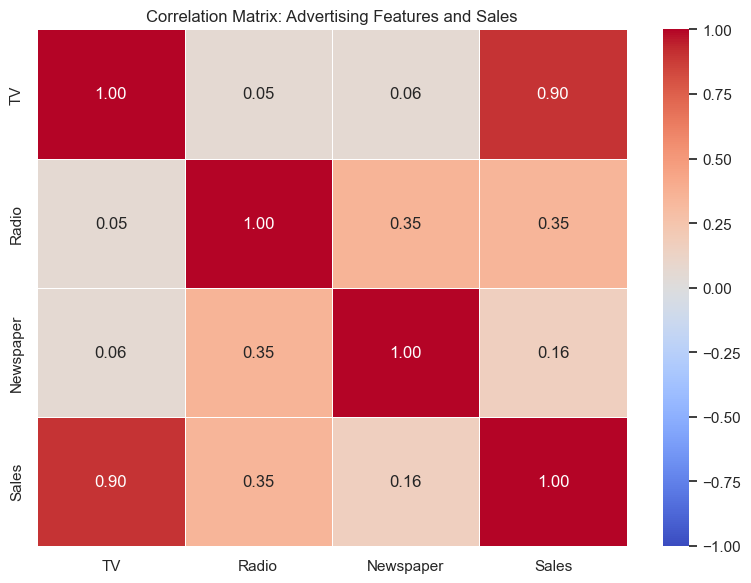

Correlation of each advertising channel with Sales:


,Correlation with Sales
TV,0.901
Radio,0.350
Newspaper,0.158


In [13]:
correlation_matrix = df.corr(numeric_only=True)

plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1
)
plt.title("Correlation Matrix: Advertising Features and Sales")
plt.tight_layout()
plt.show()

print("Correlation of each advertising channel with Sales:")
display(correlation_matrix["Sales"].drop("Sales").sort_values(ascending=False).to_frame("Correlation with Sales"))

## 8. Prepare Data for Machine Learning

### 8.1 Import Machine-Learning Libraries

In [14]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Machine-learning libraries imported successfully.")

Machine-learning libraries imported successfully.


In [15]:
# Predictor variables and target variable
X = df[["TV", "Radio", "Newspaper"]]
y = df["Sales"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training feature shape: (160, 3)
Testing feature shape: (40, 3)
Training target shape: (160,)
Testing target shape: (40,)


## 9. Model 1: Linear Regression (Baseline)

Linear Regression is the baseline model. It estimates a linear relationship between advertising expenditure and sales.

The model is fitted only on the training data. Its performance is then measured on the held-out test data.

In [16]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_test)

print("Linear Regression model trained successfully.")

Linear Regression model trained successfully.


### 9.1 Linear Regression Coefficients

In [17]:
linear_coefficients = pd.DataFrame({
    "Advertising Channel": X.columns,
    "Coefficient": linear_model.coef_
})

display(linear_coefficients.sort_values("Coefficient", ascending=False))
print("Intercept:", linear_model.intercept_)

,Advertising Channel,Coefficient
1,Radio,0.101
0,TV,0.055
2,Newspaper,0.004


Intercept: 4.714126402214129


## 10. Model 2: Polynomial Regression

Polynomial Regression can model curved relationships by adding polynomial combinations of the original features.

A pipeline keeps feature transformation and model fitting together. It is fitted only on the training data, helping prevent information from the test set leaking into training.

In [18]:
polynomial_model = Pipeline([
    ("polynomial_features", PolynomialFeatures(degree=2, include_bias=False)),
    ("linear_regression", LinearRegression())
])

polynomial_model.fit(X_train, y_train)
polynomial_predictions = polynomial_model.predict(X_test)

print("Polynomial Regression model trained successfully.")

Polynomial Regression model trained successfully.


## 11. Model 3: Random Forest Regressor

Random Forest is an ensemble model that combines predictions from multiple decision trees. It can capture non-linear patterns and interactions between features.

The model is trained with a fixed random state so the result is reproducible.

In [19]:
random_forest_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    min_samples_leaf=2
)

random_forest_model.fit(X_train, y_train)
random_forest_predictions = random_forest_model.predict(X_test)

print("Random Forest Regressor trained successfully.")

Random Forest Regressor trained successfully.


## 12. Model Evaluation: MAE, RMSE, and R²

In [20]:
def calculate_regression_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    return mae, rmse, r2

model_predictions = {
    "Linear Regression": linear_predictions,
    "Polynomial Regression (Degree 2)": polynomial_predictions,
    "Random Forest": random_forest_predictions
}

evaluation_results = []

for model_name, predictions in model_predictions.items():
    mae, rmse, r2 = calculate_regression_metrics(y_test, predictions)
    evaluation_results.append({
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

results_df = pd.DataFrame(evaluation_results).sort_values("RMSE").reset_index(drop=True)
display(results_df.style.format({
    "MAE": "{:.4f}",
    "RMSE": "{:.4f}",
    "R2 Score": "{:.4f}"
}))

,Model,MAE,RMSE,R2 Score
0,Random Forest,0.8871,1.1810,0.9549
1,Polynomial Regression (Degree 2),0.9034,1.2011,0.9533
2,Linear Regression,1.2748,1.7052,0.9059


### 12.1 Select the Best Model

In [21]:
best_model_name = results_df.loc[0, "Model"]
best_rmse = results_df.loc[0, "RMSE"]

print("Best model based on lowest test RMSE:", best_model_name)
print(f"Test RMSE: {best_rmse:.4f}")

best_predictions = model_predictions[best_model_name]

Best model based on lowest test RMSE: Random Forest
Test RMSE: 1.1810


## 13. Actual vs. Predicted Sales

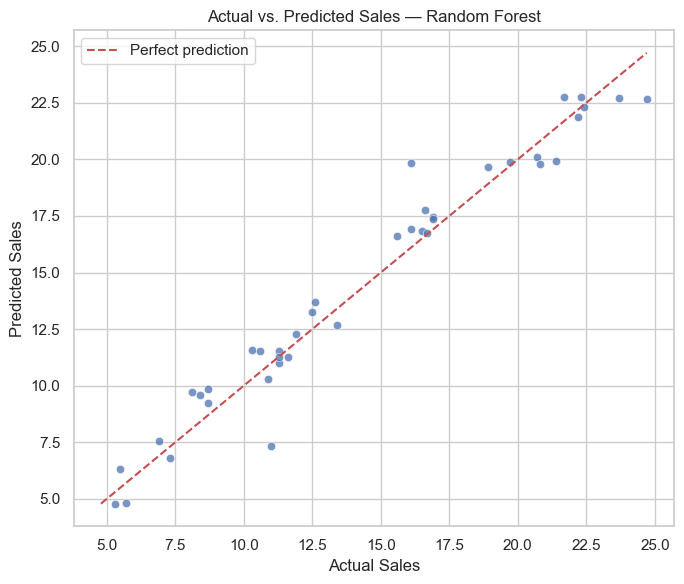

In [22]:
plt.figure(figsize=(7, 6))
sns.scatterplot(x=y_test, y=best_predictions, alpha=0.75)

min_value = min(y_test.min(), np.min(best_predictions))
max_value = max(y_test.max(), np.max(best_predictions))
plt.plot([min_value, max_value], [min_value, max_value], "r--", label="Perfect prediction")

plt.title(f"Actual vs. Predicted Sales — {best_model_name}")
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.legend()
plt.tight_layout()
plt.show()

## 14. Residual Plot for the Best Model

A residual is the difference between the actual value and the predicted value:

**Residual = Actual Sales − Predicted Sales**

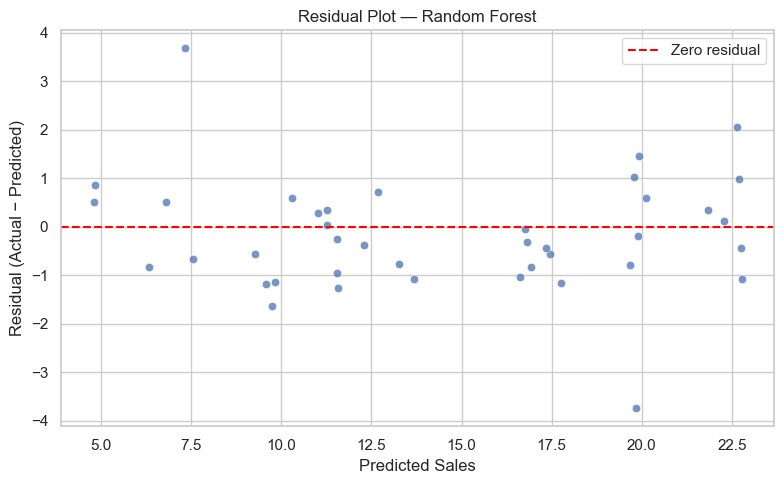

In [23]:
residuals = y_test.to_numpy() - np.asarray(best_predictions)

plt.figure(figsize=(8, 5))
sns.scatterplot(x=best_predictions, y=residuals, alpha=0.75)
plt.axhline(y=0, color="red", linestyle="--", label="Zero residual")

plt.title(f"Residual Plot — {best_model_name}")
plt.xlabel("Predicted Sales")
plt.ylabel("Residual (Actual − Predicted)")
plt.legend()
plt.tight_layout()
plt.show()

### 14.1 Residual Distribution

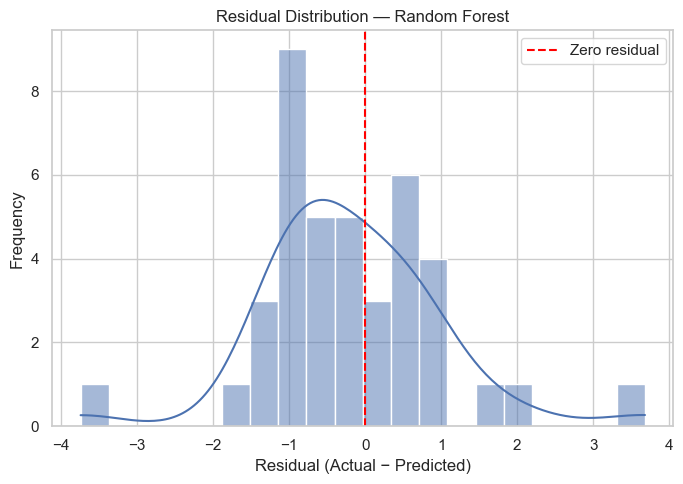

Mean residual: -0.1803
Residual standard deviation: 1.1821


In [24]:
plt.figure(figsize=(7, 5))
sns.histplot(residuals, kde=True, bins=20)
plt.axvline(0, color="red", linestyle="--", label="Zero residual")
plt.title(f"Residual Distribution — {best_model_name}")
plt.xlabel("Residual (Actual − Predicted)")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Mean residual: {np.mean(residuals):.4f}")
print(f"Residual standard deviation: {np.std(residuals, ddof=1):.4f}")

## 15. Advertising Channel Impact

The project asks which advertising channel has the highest impact on sales.

We report:
1. **Linear Regression coefficients**, which show the estimated change in sales per one-unit increase in each channel, holding the other channels constant.
2. **Random Forest feature importance**, which indicates how much each feature contributes to reducing prediction error across the trees.

In [25]:
# Linear Regression coefficient comparison
coefficient_impact = pd.DataFrame({
    "Channel": X.columns,
    "Linear Regression Coefficient": linear_model.coef_
})
coefficient_impact["Absolute Coefficient"] = coefficient_impact["Linear Regression Coefficient"].abs()
coefficient_impact = coefficient_impact.sort_values("Absolute Coefficient", ascending=False)

print("Linear Regression coefficient comparison:")
display(coefficient_impact)

top_linear_channel = coefficient_impact.iloc[0]["Channel"]
print("Channel with the largest absolute Linear Regression coefficient:", top_linear_channel)

Linear Regression coefficient comparison:


,Channel,Linear Regression Coefficient,Absolute Coefficient
1,Radio,0.101,0.101
0,TV,0.055,0.055
2,Newspaper,0.004,0.004


Channel with the largest absolute Linear Regression coefficient: Radio


Random Forest feature importance:


,Channel,Feature Importance
0,TV,0.850
1,Radio,0.135
2,Newspaper,0.016


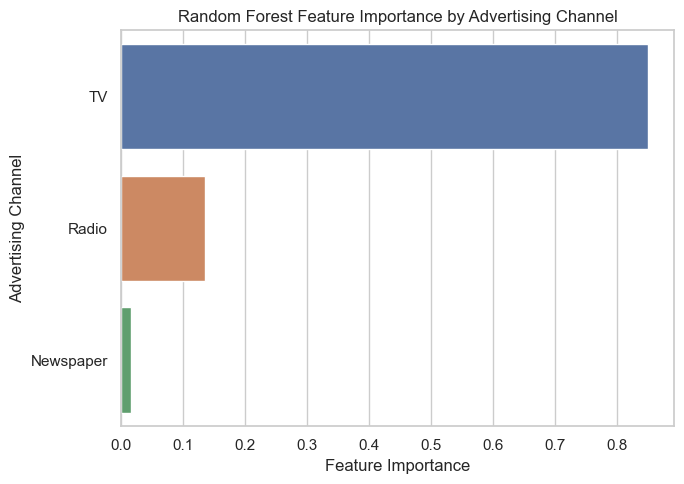

Highest Random Forest feature importance: TV


In [26]:
# Random Forest feature importance
rf_importance = pd.DataFrame({
    "Channel": X.columns,
    "Feature Importance": random_forest_model.feature_importances_
}).sort_values("Feature Importance", ascending=False)

print("Random Forest feature importance:")
display(rf_importance)

plt.figure(figsize=(7, 5))
sns.barplot(data=rf_importance, x="Feature Importance", y="Channel")
plt.title("Random Forest Feature Importance by Advertising Channel")
plt.xlabel("Feature Importance")
plt.ylabel("Advertising Channel")
plt.tight_layout()
plt.show()

print("Highest Random Forest feature importance:", rf_importance.iloc[0]["Channel"])

## 16. Predict Sales for a New Advertising Budget

In [27]:
# Enter hypothetical advertising expenditure values in the dataset's units
new_advertising_budget = pd.DataFrame({
    "TV": [100],
    "Radio": [25],
    "Newspaper": [20]
})

# Select the model that achieved the lowest test RMSE
best_model_objects = {
    "Linear Regression": linear_model,
    "Polynomial Regression (Degree 2)": polynomial_model,
    "Random Forest": random_forest_model
}

selected_model = best_model_objects[best_model_name]
predicted_sales = selected_model.predict(new_advertising_budget)[0]

print("Advertising budget:")
display(new_advertising_budget)
print(f"Predicted Sales using {best_model_name}: {predicted_sales:.3f}")

Advertising budget:


,TV,Radio,Newspaper
0,100,25,20


Predicted Sales using Random Forest: 13.033


## 17. Project Findings and Business Interpretation

In [28]:
best_row = results_df.iloc[0]

print("PROJECT SUMMARY")
print("-" * 60)
print(f"Number of observations used: {len(df)}")
print(f"Predictor features: {', '.join(X.columns)}")
print(f"Best model by test RMSE: {best_model_name}")
print(f"Test MAE: {best_row['MAE']:.4f}")
print(f"Test RMSE: {best_row['RMSE']:.4f}")
print(f"Test R²: {best_row['R2 Score']:.4f}")
print(f"Highest Random Forest feature importance: {rf_importance.iloc[0]['Channel']}")
print(f"Largest absolute Linear Regression coefficient: {top_linear_channel}")

PROJECT SUMMARY
------------------------------------------------------------
Number of observations used: 200
Predictor features: TV, Radio, Newspaper
Best model by test RMSE: Random Forest
Test MAE: 0.8871
Test RMSE: 1.1810
Test R²: 0.9549
Highest Random Forest feature importance: TV
Largest absolute Linear Regression coefficient: Radio


## 18. Limitations and Future Improvements

### Limitations
1. The dataset is relatively small, so performance may vary with a different train/test split.
2. The dataset contains only three advertising channels and may omit other factors that influence sales.
3. Historical relationships may not remain stable in future campaigns or markets.
4. Feature importance and regression coefficients describe model relationships, not proof of causation.
5. A single train/test split provides only one estimate of model performance.

### Future improvements
1. Use cross-validation for more stable model comparison.
2. Test additional models and tune hyperparameters using training data only.
3. Include relevant variables such as product category, season, region, pricing, and campaign timing if available.
4. Evaluate the model on newer, independent campaign data before using it for operational decisions.

# THANK YOU